In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:

from google.colab import drive
drive.mount('/content/drive')

DATASET_PATH = "/content/drive/MyDrive/Orange Dataset.zip"

import os

print("File exists:", os.path.exists(DATASET_PATH))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
File exists: True


In [ ]:
from pathlib import Path

DATASET_PATH = Path("/content/drive/MyDrive/Orange Dataset.zip")
EXTRACT_PATH = Path("/content/drive/MyDrive/Orange_Dataset_Extracted")

print("ZIP file exists:", DATASET_PATH.is_file())
print("Extracted folder exists:", EXTRACT_PATH.is_dir())

if EXTRACT_PATH.is_dir():
    print("Dataset folders:", [p.name for p in EXTRACT_PATH.iterdir()])

ZIP file exists: True
Extracted folder exists: True
Dataset folders: ['test', 'train']


In [ ]:
import os

for root, dirs, files in os.walk(str(EXTRACT_PATH)):
    print(root, "| folders:", dirs, "| files:", len(files))

    if root.count(os.sep) - str(EXTRACT_PATH).count(os.sep) >= 2:
        dirs[:] = []


/content/drive/MyDrive/Orange_Dataset_Extracted | folders: ['test', 'train'] | files: 0
/content/drive/MyDrive/Orange_Dataset_Extracted/test | folders: ['blackspot', 'canker', 'fresh', 'grenning'] | files: 0
/content/drive/MyDrive/Orange_Dataset_Extracted/test/blackspot | folders: [] | files: 22
/content/drive/MyDrive/Orange_Dataset_Extracted/test/canker | folders: [] | files: 22
/content/drive/MyDrive/Orange_Dataset_Extracted/test/fresh | folders: [] | files: 33
/content/drive/MyDrive/Orange_Dataset_Extracted/test/grenning | folders: [] | files: 22
/content/drive/MyDrive/Orange_Dataset_Extracted/train | folders: ['blackspot', 'canker', 'fresh', 'grenning'] | files: 0
/content/drive/MyDrive/Orange_Dataset_Extracted/train/blackspot | folders: [] | files: 184
/content/drive/MyDrive/Orange_Dataset_Extracted/train/canker | folders: [] | files: 179
/content/drive/MyDrive/Orange_Dataset_Extracted/train/fresh | folders: [] | files: 281
/content/drive/MyDrive/Orange_Dataset_Extracted/train/gre

In [ ]:

from pathlib import Path

DATASET_PATH = Path(
    "/content/drive/MyDrive/Orange_Dataset_Extracted"
)

TRAIN_PATH = DATASET_PATH / "train"
TEST_PATH = DATASET_PATH / "test"

print("Train folder exists:", TRAIN_PATH.exists())
print("Test folder exists:", TEST_PATH.exists())
print("Classes:", sorted(p.name for p in TRAIN_PATH.iterdir() if p.is_dir()))


Train folder exists: True
Test folder exists: True
Classes: ['blackspot', 'canker', 'fresh', 'grenning']


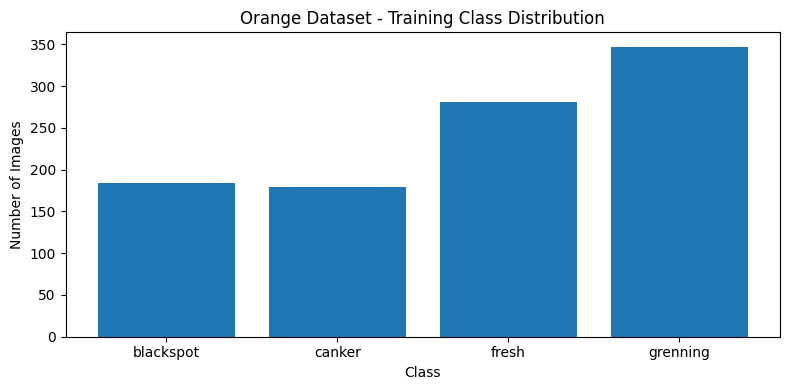

blackspot: 184 images
canker: 179 images
fresh: 281 images
grenning: 347 images


In [ ]:

import matplotlib.pyplot as plt

classes = sorted(
    p.name for p in TRAIN_PATH.iterdir() if p.is_dir()
)

counts = [
    sum(1 for f in (TRAIN_PATH / cls).iterdir() if f.is_file())
    for cls in classes
]

plt.figure(figsize=(8, 4))
plt.bar(classes, counts)
plt.title("Orange Dataset - Training Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.tight_layout()
plt.show()

for cls, count in zip(classes, counts):
    print(f"{cls}: {count} images")


Classes found: ['blackspot', 'canker', 'fresh', 'grenning']


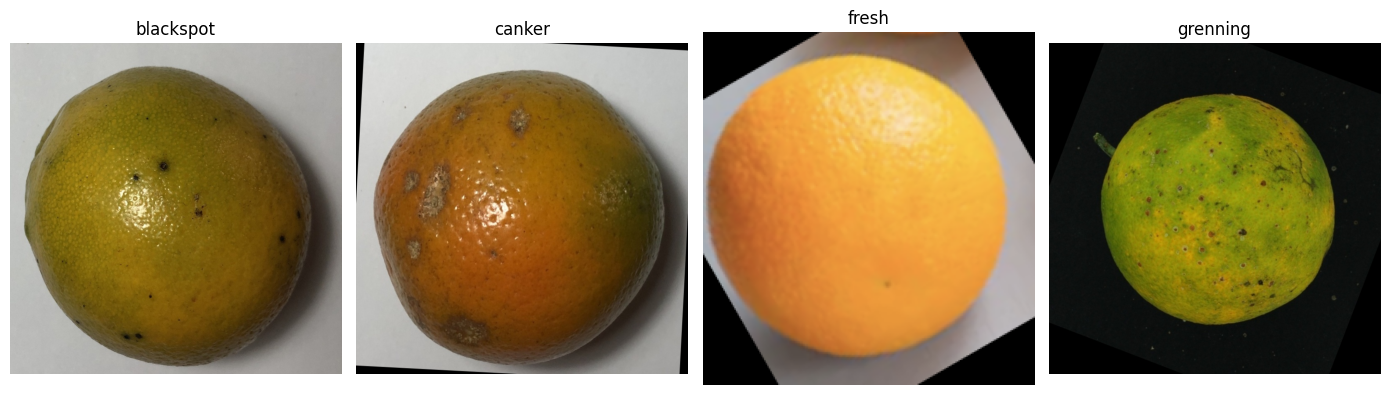

In [ ]:

from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import random

# Dataset path
TRAIN_PATH = Path(
    "/content/drive/MyDrive/Orange_Dataset_Extracted/train"
)

# Check the folder
if not TRAIN_PATH.exists():
    raise FileNotFoundError(
        f"Training folder not found: {TRAIN_PATH}"
    )

# Define classes
classes = sorted(
    folder.name
    for folder in TRAIN_PATH.iterdir()
    if folder.is_dir()
)

print("Classes found:", classes)

# Display sample images
fig, axes = plt.subplots(
    1, len(classes), figsize=(14, 4)
)

for ax, cls in zip(axes, classes):
    folder = TRAIN_PATH / cls

    images = [
        f for f in folder.iterdir()
        if f.is_file()
        and f.suffix.lower() in {
            ".jpg", ".jpeg", ".png", ".bmp", ".webp"
        }
    ]

    if images:
        image_path = random.choice(images)

        with Image.open(image_path) as img:
            ax.imshow(img.convert("RGB"))

        ax.set_title(cls)
    else:
        ax.set_title(f"{cls}\nNo images")

    ax.axis("off")

plt.tight_layout()
plt.show()



Dataset quality report
-----------------------------------
blackspot: Train = 184, Test = 22
canker: Train = 179, Test = 22
fresh: Train = 281, Test = 33
grenning: Train = 347, Test = 22

Total training images: 991
Total testing images: 99
Unreadable images: 1
Examples: ['/content/drive/MyDrive/Orange_Dataset_Extracted/train/grenning/g (252).jpg']


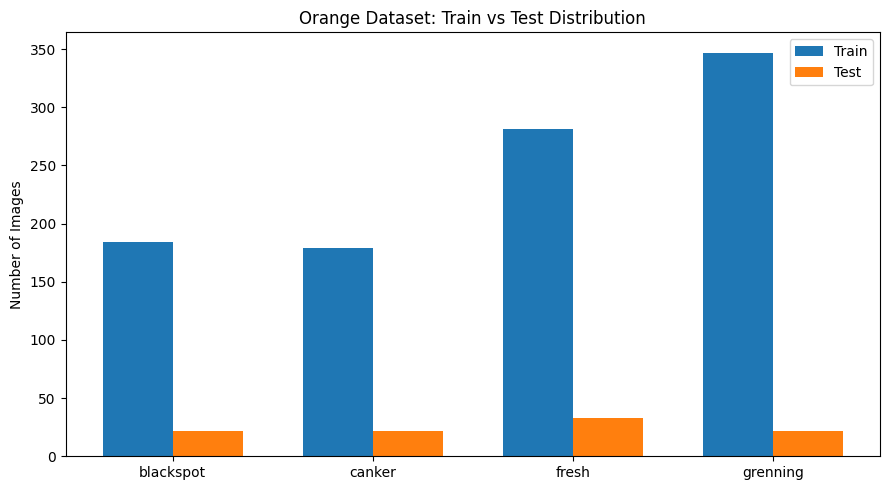

In [ ]:

from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

DATASET_PATH = Path(
    "/content/drive/MyDrive/Orange_Dataset_Extracted"
)

TRAIN_PATH = DATASET_PATH / "train"
TEST_PATH = DATASET_PATH / "test"

classes = sorted(
    folder.name for folder in TRAIN_PATH.iterdir()
    if folder.is_dir()
)

extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

train_counts = []
test_counts = []
corrupt_images = []

for cls in classes:
    for split_path in [TRAIN_PATH, TEST_PATH]:
        folder = split_path / cls
        images = [
            f for f in folder.rglob("*")
            if f.is_file() and f.suffix.lower() in extensions
        ]

        if split_path == TRAIN_PATH:
            train_counts.append(len(images))
        else:
            test_counts.append(len(images))

        for image_path in images:
            try:
                with Image.open(image_path) as img:
                    img.verify()
            except Exception:
                corrupt_images.append(str(image_path))

print("Dataset quality report")
print("-" * 35)

for i, cls in enumerate(classes):
    print(
        f"{cls}: Train = {train_counts[i]}, "
        f"Test = {test_counts[i]}"
    )

print("\nTotal training images:", sum(train_counts))
print("Total testing images:", sum(test_counts))
print("Unreadable images:", len(corrupt_images))

if corrupt_images:
    print("Examples:", corrupt_images[:5])

plt.figure(figsize=(9, 5))
x = range(len(classes))
width = 0.35

plt.bar(
    [i - width/2 for i in x],
    train_counts,
    width=width,
    label="Train"
)
plt.bar(
    [i + width/2 for i in x],
    test_counts,
    width=width,
    label="Test"
)

plt.xticks(list(x), classes)
plt.ylabel("Number of Images")
plt.title("Orange Dataset: Train vs Test Distribution")
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:

!pip -q install scikit-learn scikit-image


In [ ]:

from pathlib import Path
from sklearn.model_selection import train_test_split
from collections import Counter
import shutil
import random

DATASET_PATH = Path(
    "/content/drive/MyDrive/Orange_Dataset_Extracted"
)

TRAIN_PATH = DATASET_PATH / "train"
TEST_PATH = DATASET_PATH / "test"

SPLIT_PATH = Path("/content/orange_prepared")

# Supported image extensions
extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

classes = sorted(
    folder.name for folder in TRAIN_PATH.iterdir()
    if folder.is_dir()
)

# Collect image paths and labels
image_paths = []
labels = []

for cls in classes:
    for path in (TRAIN_PATH / cls).rglob("*"):
        if path.is_file() and path.suffix.lower() in extensions:
            image_paths.append(str(path))
            labels.append(cls)

# Stratified train-validation split
train_files, val_files, y_train, y_val = train_test_split(
    image_paths,
    labels,
    test_size=0.20,
    random_state=42,
    stratify=labels
)

# Recreate prepared folders
if SPLIT_PATH.exists():
    shutil.rmtree(SPLIT_PATH)

for split in ["train", "val"]:
    for cls in classes:
        (SPLIT_PATH / split / cls).mkdir(
            parents=True, exist_ok=True
        )

# Copy images, keeping original files unchanged
for path, cls in zip(train_files, y_train):
    shutil.copy2(
        path, SPLIT_PATH / "train" / cls / Path(path).name
    )

for path, cls in zip(val_files, y_val):
    shutil.copy2(
        path, SPLIT_PATH / "val" / cls / Path(path).name
    )

print("Training images:", len(train_files))
print("Validation images:", len(val_files))
print("Test images:", sum(
    1 for cls in classes
    for p in (TEST_PATH / cls).rglob("*")
    if p.is_file() and p.suffix.lower() in extensions
))

print("\nTraining distribution:", Counter(y_train))
print("Validation distribution:", Counter(y_val))
print("\nPrepared folders:", SPLIT_PATH)


Training images: 792
Validation images: 199
Test images: 99

Training distribution: Counter({'grenning': 277, 'fresh': 225, 'blackspot': 147, 'canker': 143})
Validation distribution: Counter({'grenning': 70, 'fresh': 56, 'blackspot': 37, 'canker': 36})

Prepared folders: /content/orange_prepared


In [ ]:

import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

TRAIN_DIR = "/content/orange_prepared/train"
VAL_DIR = "/content/orange_prepared/val"
TEST_DIR = "/content/drive/MyDrive/Orange_Dataset_Extracted/test"

# Pretrained MobileNetV2 normalization
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

train_ds = datasets.ImageFolder(
    TRAIN_DIR, transform=train_transform
)
val_ds = datasets.ImageFolder(
    VAL_DIR, transform=eval_transform
)
test_ds = datasets.ImageFolder(
    TEST_DIR, transform=eval_transform
)

assert train_ds.classes == val_ds.classes == test_ds.classes

train_loader = DataLoader(
    train_ds, batch_size=32, shuffle=True
)
val_loader = DataLoader(
    val_ds, batch_size=32, shuffle=False
)
test_loader = DataLoader(
    test_ds, batch_size=32, shuffle=False
)

print("Classes:", train_ds.classes)
print("Train:", len(train_ds))
print("Validation:", len(val_ds))
print("Test:", len(test_ds))
print("GPU available:", torch.cuda.is_available())


Classes: ['blackspot', 'canker', 'fresh', 'grenning']
Train: 792
Validation: 199
Test: 99
GPU available: False


Training device: cpu
Classes: ['blackspot', 'canker', 'fresh', 'grenning']
Skipping unreadable image: /content/drive/MyDrive/Orange_Dataset_Extracted/train/grenning/g (252).jpg

Readable training images: 990
Readable test images: 99
Unreadable files skipped: 1

Training distribution:
blackspot 184
canker 179
fresh 281
grenning 346

Test distribution:
blackspot 22
canker 22
fresh 33
grenning 22

Training split: 792
Validation split: 198
Test split: 99

Data loaders created successfully.
Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 64.9MB/s]


Loaded pretrained ImageNet weights.
Epoch 01/12 | Train Loss: 0.7598 | Train Acc: 0.8447 | Val Loss: 0.4103 | Val Acc: 0.9747
Epoch 02/12 | Train Loss: 0.3208 | Train Acc: 0.9558 | Val Loss: 0.2552 | Val Acc: 0.9848
Epoch 03/12 | Train Loss: 0.2297 | Train Acc: 0.9583 | Val Loss: 0.1927 | Val Acc: 0.9949
Epoch 04/12 | Train Loss: 0.2169 | Train Acc: 0.9634 | Val Loss: 0.1410 | Val Acc: 0.9949
Epoch 05/12 | Train Loss: 0.1434 | Train Acc: 0.9760 | Val Loss: 0.1217 | Val Acc: 0.9949
Epoch 06/12 | Train Loss: 0.1750 | Train Acc: 0.9609 | Val Loss: 0.1034 | Val Acc: 0.9949
Epoch 07/12 | Train Loss: 0.1431 | Train Acc: 0.9722 | Val Loss: 0.0994 | Val Acc: 0.9949
Epoch 08/12 | Train Loss: 0.1302 | Train Acc: 0.9710 | Val Loss: 0.0815 | Val Acc: 0.9949
Epoch 09/12 | Train Loss: 0.1143 | Train Acc: 0.9760 | Val Loss: 0.0814 | Val Acc: 1.0000
Epoch 10/12 | Train Loss: 0.1031 | Train Acc: 0.9811 | Val Loss: 0.0753 | Val Acc: 0.9899
Epoch 11/12 | Train Loss: 0.1070 | Train Acc: 0.9735 | Val Loss:

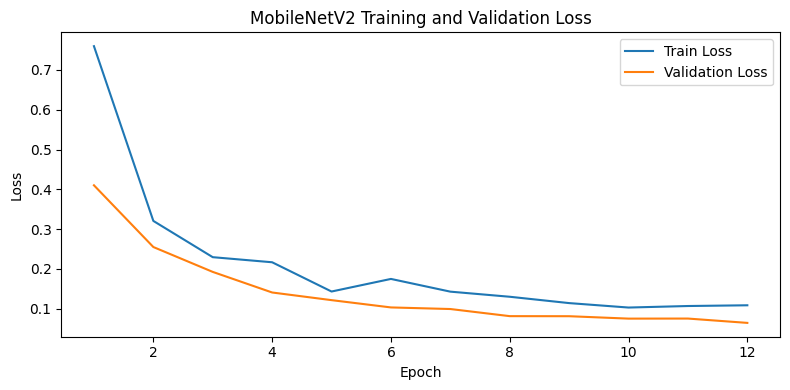

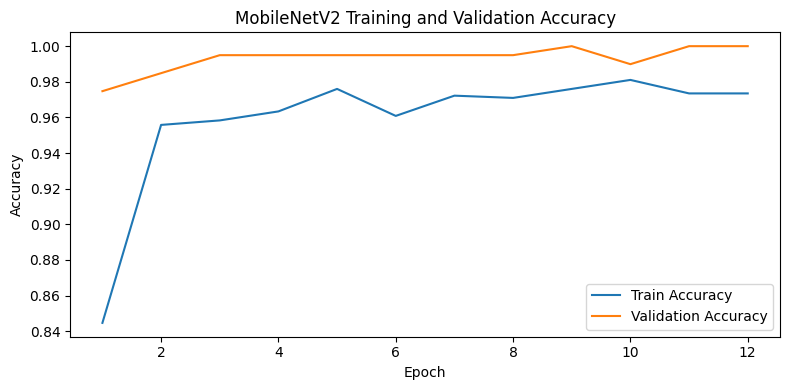


========== FINAL TEST RESULTS ==========
Test accuracy: 0.9495
Macro F1-score: 0.9445

Classification report:
              precision    recall  f1-score   support

   blackspot       0.91      0.91      0.91        22
      canker       0.90      0.86      0.88        22
       fresh       0.97      1.00      0.99        33
    grenning       1.00      1.00      1.00        22

    accuracy                           0.95        99
   macro avg       0.95      0.94      0.94        99
weighted avg       0.95      0.95      0.95        99



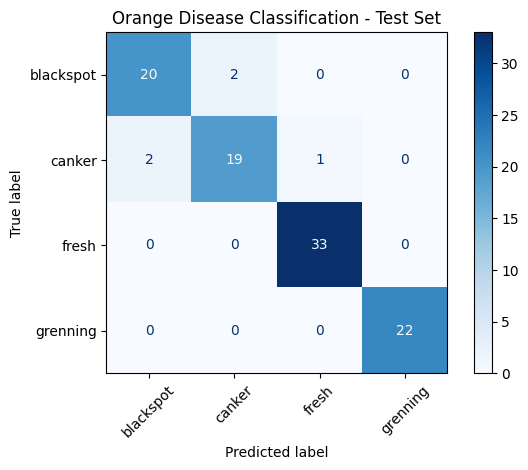


Training and evaluation completed.
To predict an image, run:
predict_orange("/path/to/your/orange_image.jpg")


In [ ]:

# ============================================================
# ORANGE DISEASE CLASSIFICATION USING MOBILENETV2
# Complete Google Colab code: data cleaning, training, testing
# ============================================================

import os
import time
import copy
import random
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageFile

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms, models

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score
)

# -------------------- 1. CONFIGURATION --------------------

SEED = 42
BATCH_SIZE = 16
MAX_EPOCHS = 12
PATIENCE = 3
IMAGE_SIZE = 224

DATASET_PATH = Path(
    "/content/drive/MyDrive/Orange_Dataset_Extracted"
)
TRAIN_PATH = DATASET_PATH / "train"
TEST_PATH = DATASET_PATH / "test"

MODEL_PATH = Path(
    "/content/drive/MyDrive/best_orange_mobilenet.pth"
)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)
print("Training device:", device)

if not TRAIN_PATH.is_dir() or not TEST_PATH.is_dir():
    raise FileNotFoundError(
        "Dataset folders were not found. Check that Google Drive "
        "is mounted and Orange_Dataset_Extracted contains train/test."
    )

# -------------------- 2. FIND CLASSES --------------------

classes = sorted([
    p.name for p in TRAIN_PATH.iterdir()
    if p.is_dir()
])

if len(classes) < 2:
    raise ValueError(
        "At least two class folders are required."
    )

missing_test_classes = [
    c for c in classes if not (TEST_PATH / c).is_dir()
]

if missing_test_classes:
    raise FileNotFoundError(
        f"Missing test class folders: {missing_test_classes}"
    )

print("Classes:", classes)

EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# -------------------- 3. CHECK IMAGE FILES --------------------

def collect_valid_images(folder, class_names):
    records = []
    unreadable = []

    for label, class_name in enumerate(class_names):
        class_folder = folder / class_name

        for path in sorted(class_folder.rglob("*")):
            if not path.is_file():
                continue

            if path.suffix.lower() not in EXTENSIONS:
                continue

            try:
                with Image.open(path) as image:
                    image.verify()

                # Also verify the image can actually be decoded.
                with Image.open(path) as image:
                    image.convert("RGB").load()

                records.append((str(path), label))

            except Exception as error:
                unreadable.append(str(path))
                print("Skipping unreadable image:", path)

    return records, unreadable


train_records, bad_train = collect_valid_images(
    TRAIN_PATH, classes
)
test_records, bad_test = collect_valid_images(
    TEST_PATH, classes
)

if not train_records:
    raise ValueError("No readable training images were found.")

if not test_records:
    raise ValueError("No readable test images were found.")

print("\nReadable training images:", len(train_records))
print("Readable test images:", len(test_records))
print("Unreadable files skipped:", len(bad_train) + len(bad_test))

print("\nTraining distribution:")
for i, name in enumerate(classes):
    print(name, sum(label == i for _, label in train_records))

print("\nTest distribution:")
for i, name in enumerate(classes):
    print(name, sum(label == i for _, label in test_records))

# -------------------- 4. STRATIFIED TRAIN/VALIDATION SPLIT --------------------

all_paths = [path for path, label in train_records]
all_labels = [label for path, label in train_records]

train_files, val_files, y_train, y_val = train_test_split(
    all_paths,
    all_labels,
    test_size=0.20,
    random_state=SEED,
    stratify=all_labels
)

print("\nTraining split:", len(train_files))
print("Validation split:", len(val_files))
print("Test split:", len(test_records))

# -------------------- 5. IMAGE TRANSFORMS --------------------

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(
        brightness=0.12,
        contrast=0.12
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# -------------------- 6. CUSTOM DATASET --------------------

class OrangeDataset(Dataset):
    def __init__(self, paths, labels, transform=None):
        self.paths = paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        path = self.paths[index]
        label = self.labels[index]

        with Image.open(path) as image:
            image = image.convert("RGB")

            if self.transform:
                image = self.transform(image)

        return image, label


train_ds = OrangeDataset(
    train_files, y_train, train_transform
)

val_ds = OrangeDataset(
    val_files, y_val, eval_transform
)

test_files = [path for path, label in test_records]
y_test = [label for path, label in test_records]

test_ds = OrangeDataset(
    test_files, y_test, eval_transform
)

train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE,
    shuffle=True, num_workers=0
)

val_loader = DataLoader(
    val_ds, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=0
)

test_loader = DataLoader(
    test_ds, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=0
)

print("\nData loaders created successfully.")

# -------------------- 7. LOAD MOBILENETV2 --------------------

try:
    weights = models.MobileNet_V2_Weights.DEFAULT
    model = models.mobilenet_v2(weights=weights)
    print("Loaded pretrained ImageNet weights.")
except Exception as error:
    print("Pretrained weights unavailable:", error)
    print("Using randomly initialized weights instead.")
    model = models.mobilenet_v2(weights=None)

# Freeze feature extractor initially
for parameter in model.features.parameters():
    parameter.requires_grad = False

# Replace final classifier
num_classes = len(classes)

model.classifier[1] = nn.Linear(
    model.last_channel, num_classes
)

model = model.to(device)

# -------------------- 8. HANDLE CLASS IMBALANCE --------------------

class_weights_np = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(num_classes),
    y=np.array(y_train)
)

class_weights = torch.tensor(
    class_weights_np,
    dtype=torch.float32,
    device=device
)

criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

optimizer = torch.optim.Adam(
    model.classifier.parameters(),
    lr=0.001
)

# -------------------- 9. TRAINING FUNCTION --------------------

def run_epoch(loader, training=False):
    if training:
        model.train()
    else:
        model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    with torch.set_grad_enabled(training):
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            if training:
                optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            if training:
                loss.backward()
                optimizer.step()

            batch_size = labels.size(0)

            total_loss += loss.item() * batch_size
            correct += (
                outputs.argmax(dim=1) == labels
            ).sum().item()

            total += batch_size

    return total_loss / total, correct / total


# -------------------- 10. TRAIN WITH EARLY STOPPING --------------------

best_val_loss = float("inf")
best_state = None
wait = 0
history = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": []
}

start_time = time.time()

for epoch in range(MAX_EPOCHS):

    train_loss, train_acc = run_epoch(
        train_loader, training=True
    )

    val_loss, val_acc = run_epoch(
        val_loader, training=False
    )

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_accuracy"].append(train_acc)
    history["val_accuracy"].append(val_acc)

    print(
        f"Epoch {epoch + 1:02d}/{MAX_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = copy.deepcopy(model.state_dict())
        wait = 0
    else:
        wait += 1

        if wait >= PATIENCE:
            print("Early stopping triggered.")
            break

if best_state is None:
    raise RuntimeError("Training did not produce a model checkpoint.")

model.load_state_dict(best_state)

# Save model weights and class labels
torch.save({
    "model_state_dict": model.state_dict(),
    "classes": classes,
    "image_size": IMAGE_SIZE
}, MODEL_PATH)

print("\nBest model saved to:", MODEL_PATH)
print(f"Training time: {(time.time() - start_time) / 60:.2f} minutes")

# -------------------- 11. PLOT TRAINING HISTORY --------------------

epochs = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(8, 4))
plt.plot(epochs, history["train_loss"], label="Train Loss")
plt.plot(epochs, history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("MobileNetV2 Training and Validation Loss")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(
    epochs, history["train_accuracy"],
    label="Train Accuracy"
)
plt.plot(
    epochs, history["val_accuracy"],
    label="Validation Accuracy"
)
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("MobileNetV2 Training and Validation Accuracy")
plt.legend()
plt.tight_layout()
plt.show()

# -------------------- 12. FINAL TEST EVALUATION --------------------

checkpoint = torch.load(
    MODEL_PATH, map_location=device
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

y_true = []
y_pred = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1).cpu().tolist()

        y_pred.extend(predictions)
        y_true.extend(labels.tolist())

test_accuracy = accuracy_score(y_true, y_pred)
macro_f1 = f1_score(
    y_true, y_pred, average="macro", zero_division=0
)

print("\n========== FINAL TEST RESULTS ==========")
print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Macro F1-score: {macro_f1:.4f}")

print("\nClassification report:")
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(num_classes)),
    target_names=classes,
    zero_division=0
))

cm = confusion_matrix(
    y_true, y_pred,
    labels=list(range(num_classes))
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
)

disp.plot(xticks_rotation=45, cmap="Blues")
plt.title("Orange Disease Classification - Test Set")
plt.tight_layout()
plt.show()

# -------------------- 13. PREDICT ONE NEW IMAGE --------------------

def predict_orange(image_path):
    image_path = Path(image_path)

    if not image_path.is_file():
        print("Image file not found:", image_path)
        return

    try:
        with Image.open(image_path) as image:
            image = image.convert("RGB")
            display_image = image.copy()
            input_tensor = eval_transform(image).unsqueeze(0)

        model.eval()

        with torch.no_grad():
            output = model(input_tensor.to(device))
            probabilities = torch.softmax(output, dim=1)[0]
            predicted_index = int(probabilities.argmax().item())

        print("Predicted class:", classes[predicted_index])
        print(
            "Model confidence:",
            f"{probabilities[predicted_index].item() * 100:.2f}%"
        )

        plt.figure(figsize=(4, 4))
        plt.imshow(display_image)
        plt.title(f"Prediction: {classes[predicted_index]}")
        plt.axis("off")
        plt.show()

        for i, class_name in enumerate(classes):
            print(
                f"{class_name}: "
                f"{probabilities[i].item() * 100:.2f}%"
            )

    except Exception as error:
        print("Could not predict this image:", error)


print("\nTraining and evaluation completed.")
print("To predict an image, run:")
print('predict_orange("/path/to/your/orange_image.jpg")')


Classes: ['blackspot', 'canker', 'fresh', 'grenning']
Skipping unreadable image: /content/drive/MyDrive/Orange_Dataset_Extracted/train/grenning/g (252).jpg
SVM training images: 792
Test images: 99

Extracting training features...
Processed 100/792 images
Processed 200/792 images
Processed 300/792 images
Processed 400/792 images
Processed 500/792 images
Processed 600/792 images
Processed 700/792 images

Extracting test features...
Training feature shape: (792, 8100)
Test feature shape: (99, 8100)

Training SVM...

========== SVM FINAL TEST RESULTS ==========
Test accuracy: 0.8283
Macro F1-score: 0.8069
Training time: 4.06 seconds

Classification report:
              precision    recall  f1-score   support

   blackspot       0.63      0.77      0.69        22
      canker       0.65      0.50      0.56        22
       fresh       0.97      0.97      0.97        33
    grenning       1.00      1.00      1.00        22

    accuracy                           0.83        99
   macro avg 

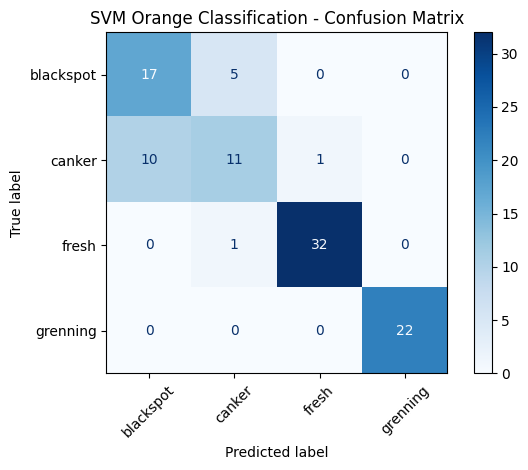


========== MODEL COMPARISON ==========
MobileNetV2 accuracy: 0.9495
SVM accuracy:         0.8283
MobileNetV2 macro F1: 0.9445
SVM macro F1:         0.8069
Higher test accuracy: MobileNetV2


In [ ]:

# ============================================
# ORANGE CLASSIFICATION USING SVM + HOG FEATURES
# ============================================

import time
import numpy as np
from pathlib import Path
from PIL import Image, UnidentifiedImageError
from skimage.feature import hog
from skimage.color import rgb2gray
from skimage.transform import resize
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Install scikit-image if it is not available
# If the import above fails, run:
# !pip install scikit-image
# Then rerun this cell.

# 1. Dataset paths
DATASET_PATH = Path("/content/drive/MyDrive/Orange_Dataset_Extracted")
TRAIN_PATH = DATASET_PATH / "train"
TEST_PATH = DATASET_PATH / "test"

classes = sorted([
    folder.name for folder in TRAIN_PATH.iterdir()
    if folder.is_dir()
])

print("Classes:", classes)

# 2. Collect readable images
def collect_images(folder):
    image_paths = []
    labels = []

    for label, class_name in enumerate(classes):
        class_folder = folder / class_name

        for path in sorted(class_folder.iterdir()):
            if path.suffix.lower() not in {
                ".jpg", ".jpeg", ".png", ".bmp", ".webp"
            }:
                continue

            try:
                with Image.open(path) as image:
                    image.verify()

                with Image.open(path) as image:
                    image.convert("RGB").load()

                image_paths.append(path)
                labels.append(label)

            except Exception:
                print("Skipping unreadable image:", path)

    return image_paths, np.array(labels, dtype=np.int64)


train_paths, train_labels = collect_images(TRAIN_PATH)
test_paths, test_labels = collect_images(TEST_PATH)

# Use the same 80/20 stratified training split as the CNN
train_indices, _ = train_test_split(
    np.arange(len(train_paths)),
    test_size=0.20,
    random_state=42,
    stratify=train_labels
)

svm_train_paths = [train_paths[i] for i in train_indices]
svm_train_labels = train_labels[train_indices]

print("SVM training images:", len(svm_train_paths))
print("Test images:", len(test_paths))

# 3. Convert each image into HOG features
def extract_hog_features(image_paths):
    features = []

    for i, path in enumerate(image_paths):
        with Image.open(path) as image:
            image = image.convert("RGB").resize((128, 128))
            image = np.array(image)

        gray = rgb2gray(image)

        feature = hog(
            gray,
            orientations=9,
            pixels_per_cell=(8, 8),
            cells_per_block=(2, 2),
            block_norm="L2-Hys"
        )

        features.append(feature)

        if (i + 1) % 100 == 0:
            print(f"Processed {i + 1}/{len(image_paths)} images")

    return np.array(features, dtype=np.float32)


print("\nExtracting training features...")
X_train = extract_hog_features(svm_train_paths)

print("\nExtracting test features...")
X_test = extract_hog_features(test_paths)

y_train = svm_train_labels
y_test = test_labels

print("Training feature shape:", X_train.shape)
print("Test feature shape:", X_test.shape)

# 4. Train SVM
svm_model = make_pipeline(
    StandardScaler(),
    SVC(
        kernel="rbf",
        C=10,
        gamma="scale",
        class_weight="balanced"
    )
)

print("\nTraining SVM...")
start_time = time.time()
svm_model.fit(X_train, y_train)
training_time = time.time() - start_time

# 5. Evaluate on the independent test set
y_pred = svm_model.predict(X_test)

test_accuracy = accuracy_score(y_test, y_pred)
macro_f1 = f1_score(
    y_test, y_pred, average="macro", zero_division=0
)

print("\n========== SVM FINAL TEST RESULTS ==========")
print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Macro F1-score: {macro_f1:.4f}")
print(f"Training time: {training_time:.2f} seconds")

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred,
    labels=np.arange(len(classes)),
    target_names=classes,
    zero_division=0
))

# 6. Confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=np.arange(len(classes))
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
)

disp.plot(cmap="Blues", values_format="d")
plt.title("SVM Orange Classification - Confusion Matrix")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 7. Compare SVM with MobileNetV2
print("\n========== MODEL COMPARISON ==========")
print(f"MobileNetV2 accuracy: {0.9495:.4f}")
print(f"SVM accuracy:         {test_accuracy:.4f}")
print(f"MobileNetV2 macro F1: {0.9445:.4f}")
print(f"SVM macro F1:         {macro_f1:.4f}")

if test_accuracy > 0.9495:
    print("Higher test accuracy: SVM")
elif test_accuracy < 0.9495:
    print("Higher test accuracy: MobileNetV2")
else:
    print("Both models have equal test accuracy.")


In [ ]:

import pandas as pd
from pathlib import Path

results = pd.DataFrame({
    "Model": ["MobileNetV2", "HOG + SVM"],
    "Test Accuracy": [0.9495, 0.8283],
    "Macro F1-score": [0.9445, 0.8069],
    "Training Time (seconds)": ["Not recorded", 3.77]
})

output_path = Path("/content/drive/MyDrive/orange_model_comparison.csv")
results.to_csv(output_path, index=False)

print(results.to_string(index=False))
print("\nResults saved to:", output_path)


      Model  Test Accuracy  Macro F1-score Training Time (seconds)
MobileNetV2         0.9495          0.9445            Not recorded
  HOG + SVM         0.8283          0.8069                    3.77

Results saved to: /content/drive/MyDrive/orange_model_comparison.csv


In [ ]:
# Find saved evaluation variables and model objects
for name, obj in list(globals().items()):
    if not name.startswith("_"):
        if any(word in name.lower() for word in
               ["accuracy", "f1", "report", "history",
                "confusion", "model", "classification"]):
            try:
                print(name, ":", str(obj)[:500])
            except Exception:
                pass

In [ ]:
# Find likely trained models in the current notebook
for name, obj in list(globals().items()):
    try:
        if hasattr(obj, "predict") and hasattr(obj, "layers"):
            print("Model variable:", name)
            print("Model type:", type(obj).__name__)
            print("Input shape:", obj.input_shape)
            print("Output shape:", obj.output_shape)
            print("-" * 40)
    except Exception:
        pass

In [ ]:
print("Possible trained models:")

for name, obj in list(globals().items()):
    if name.startswith("_"):
        continue

    try:
        if hasattr(obj, "predict") and hasattr(obj, "layers"):
            print(f"Model variable: {name}")
    except Exception:
        pass

print("\nPossible test datasets:")

for name, obj in list(globals().items()):
    if name.startswith("_"):
        continue

    try:
        if hasattr(obj, "element_spec"):
            print(f"Dataset variable: {name}")
    except Exception:
        pass

Possible trained models:

Possible test datasets:


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os

search_dirs = [
    "/content/drive/MyDrive",
    "/content"
]

extensions = (".keras", ".h5", ".hdf5", ".pkl", ".joblib")

print("Searching for saved models and result files...\n")

for base in search_dirs:
    for root, dirs, files in os.walk(base):
        # Avoid scanning unnecessary hidden folders
        dirs[:] = [d for d in dirs if not d.startswith(".")]

        for file in files:
            if file.lower().endswith(extensions):
                print(os.path.join(root, file))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Searching for saved models and result files...



In [ ]:
from pathlib import Path

root = Path("/content/drive/MyDrive")
keywords = [
    "avocado", "result", "report",
    "comparison", "history", "metric"
]
extensions = {".csv", ".json", ".txt", ".xlsx", ".png", ".jpg"}

print("Possible evaluation result files:\n")

for path in root.rglob("*"):
    if path.is_file() and path.suffix.lower() in extensions:
        if any(word in path.name.lower() for word in keywords):
            print(path)

Possible evaluation result files:

/content/drive/MyDrive/orange_model_comparison.csv


In [ ]:
import pandas as pd

file_path = "/content/drive/MyDrive/orange_model_comparison.csv"

df = pd.read_csv(file_path)
display(df)

,Model,Test Accuracy,Macro F1-score,Training Time (seconds)
0,MobileNetV2,0.9495,0.9445,Not recorded
1,HOG + SVM,0.8283,0.8069,3.77
